#**Implementation of Support Vector Machine (SVM) using a real dataset (Breast Cancer Dataset)**

**Step 1: Import Libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

**Step 2: Load Real Dataset**

In [2]:
data = load_breast_cancer()

# data.data: Numerical Value
# data.feature_names: Feature name
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add the target (output) column to the DataFrame
# Target = 0 (Malignant - Cancerous)
# Target = 1 (Benign - Non-cancerous)
df['Target'] = data.target

df.head(50)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.990,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.147100,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.71190,0.26540,0.4601,0.11890,0
1,20.570,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.070170,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.24160,0.18600,0.2750,0.08902,0
2,19.690,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.127900,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.45040,0.24300,0.3613,0.08758,0
3,11.420,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.105200,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.68690,0.25750,0.6638,0.17300,0
4,20.290,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.104300,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.40000,0.16250,0.2364,0.07678,0
5,12.450,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.080890,0.2087,0.07613,...,23.75,103.40,741.6,0.17910,0.52490,0.53550,0.17410,0.3985,0.12440,0
6,18.250,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.074000,0.1794,0.05742,...,27.66,153.20,1606.0,0.14420,0.25760,0.37840,0.19320,0.3063,0.08368,0
7,13.710,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.059850,0.2196,0.07451,...,28.14,110.60,897.0,0.16540,0.36820,0.26780,0.15560,0.3196,0.11510,0
8,13.000,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.093530,0.2350,0.07389,...,30.73,106.20,739.3,0.17030,0.54010,0.53900,0.20600,0.4378,0.10720,0
9,12.460,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.085430,0.2030,0.08243,...,40.68,97.65,711.4,0.18530,1.05800,1.10500,0.22100,0.4366,0.20750,0


In [3]:
df.shape

(569, 31)

**Step 3: Select Only Two Features (For Visualization)**

Decision boundaries can only be drawn in 2D, so we'll use only two features.

In [4]:
X = df[['mean radius', 'mean texture']]

y = df['Target']

**Step 4: Train-Test Split**

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

**Step 5: Feature Scaling**

SVM works best when features are scaled.

In [6]:
# Create an object of the StandardScaler class
scaler = StandardScaler()

# Learn the mean and standard deviation from the training data
# Then transform the training data so that:
# Mean = 0
# Standard Deviation = 1
X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

**Step 6: Train SVM Model**

In [7]:
#svm = SVC(kernel='linear')
svm = SVC(kernel='rbf')
#svm = SVC(kernel='sigmoid')
svm = SVC(kernel='poly', degree=3)
svm.fit(X_train, y_train)

SVC(kernel='poly')

**Step 7: Prediction**

In [8]:
y_pred = svm.predict(X_test)

In [9]:
y_pred

array([1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1,
       1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 0])

**Step 8: Accuracy**

In [10]:
print("Accuracy :", accuracy_score(y_test, y_pred))

Accuracy : 0.8245614035087719


**Step 9: Confusion Matrix**

In [11]:
print(confusion_matrix(y_test, y_pred))

[[25 18]
 [ 2 69]]


**Step 10: Classification Report**

In [12]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.58      0.71        43
           1       0.79      0.97      0.87        71

    accuracy                           0.82       114
   macro avg       0.86      0.78      0.79       114
weighted avg       0.84      0.82      0.81       114



Step 11: Visualize Support Vectors & Decision Boundary

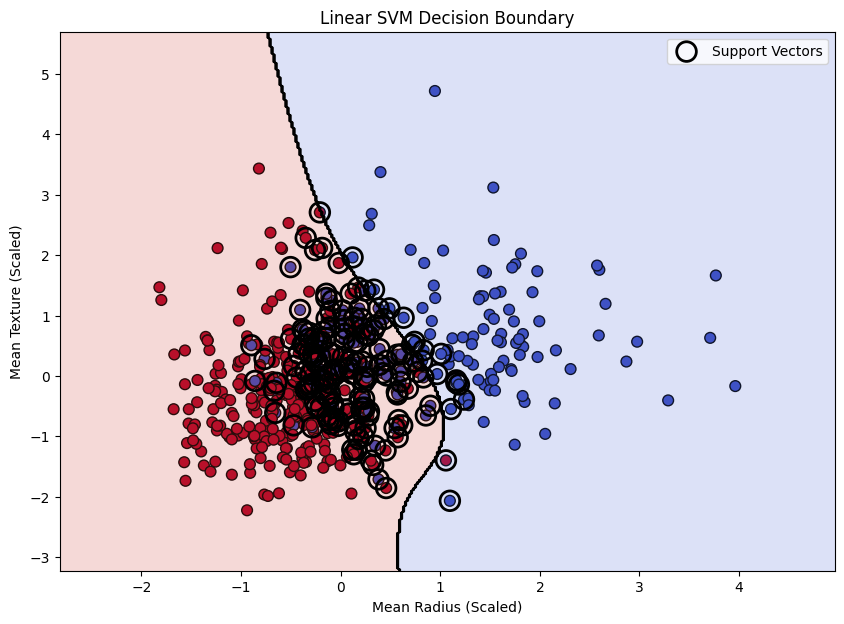

In [13]:
plt.figure(figsize=(10,7))

# Plot data points
plt.scatter(
    X_train[:,0],
    X_train[:,1],
    c=y_train,
    cmap='coolwarm',
    edgecolors='k',
    s=60
)

# Create mesh grid
x_min, x_max = X_train[:,0].min()-1, X_train[:,0].max()+1
y_min, y_max = X_train[:,1].min()-1, X_train[:,1].max()+1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Decision Boundary
plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.2,
    cmap='coolwarm'
)

# Decision Line
plt.contour(
    xx,
    yy,
    Z,
    colors='black',
    linewidths=1
)

# Support Vectors
plt.scatter(
    svm.support_vectors_[:,0],
    svm.support_vectors_[:,1],
    s=200,
    facecolors='none',
    edgecolors='black',
    linewidths=2,
    label='Support Vectors'
)

plt.xlabel("Mean Radius (Scaled)")
plt.ylabel("Mean Texture (Scaled)")
plt.title("Linear SVM Decision Boundary")

plt.legend()

plt.show()

**Expected Accuracy**

Using the two selected features, a linear SVM typically achieves around 85–92% accuracy. If you use all 30 features from the dataset (without limiting to two for visualization), accuracy is usually 95–99%.